# Baseline de classification avec Scikit-Learn

## Contexte

Après la phase d'exploration et de préparation des données, une première référence de performance doit être établie avant l'utilisation de modèles de Deep Learning.

Cette baseline permettra de :

- fournir un point de comparaison pour les futurs modèles ;
- évaluer la difficulté réelle du problème ;
- analyser les capacités d'un algorithme classique de Machine Learning sur le dataset MNIST.

## Objectif

Construire une baseline reproductible à l'aide d'une régression logistique et évaluer ses performances de manière rigoureuse.

## Questions étudiées

Cette expérimentation cherche notamment à répondre aux questions suivantes :

1. Quelle performance peut être obtenue avec un modèle classique de Machine Learning ?
2. Quel coefficient de régularisation est le plus adapté aux données ?
3. Quelle est la stabilité des performances observées lors de la validation croisée ?
4. Quelle est la performance réelle du modèle sur un jeu de validation indépendant ?
5. Quelles améliorations pourront être apportées par les futurs modèles MLP et CNN ?

## Résultats attendus

Les résultats obtenus serviront de référence pour l'ensemble des expérimentations ultérieures du projet.

---

# Protocole expérimental

## Jeux de données

Conformément au protocole défini lors de la phase d'exploration :

| Ensemble | Taille | Utilisation |
|-----------|-----------:|-----------|
| Entraînement | 54 000 | Apprentissage des modèles |
| Validation | 6 000 | Évaluation des performances |
| Test | 10 000 | Évaluation finale uniquement |

## Validation croisée

Le coefficient de régularisation de la régression logistique sera sélectionné automatiquement à l'aide d'une validation croisée à 10 folds réalisée uniquement sur l'ensemble d'entraînement.

Cette validation croisée permettra de mesurer :

- la performance moyenne du modèle ;
- sa stabilité ;
- l'incertitude associée aux performances observées.

Les indicateurs suivants seront calculés :

- Accuracy moyenne ;
- Écart-type ;
- Intervalle de confiance à 95 %.

## Évaluation finale

Une fois le meilleur modèle sélectionné :

- l'entraînement est réalisé sur l'ensemble d'entraînement ;
- l'évaluation est réalisée sur l'ensemble de validation.

Les métriques suivantes seront calculées :

- Accuracy ;
- Precision macro ;
- Recall macro ;
- F1-score macro.

## Prévention de la fuite de données

Le jeu de test n'est utilisé à aucun moment durant cette expérimentation.

Toutes les décisions de conception sont prises uniquement à partir des ensembles d'entraînement et de validation.

Le jeu de test est réservé à l'évaluation finale du projet conformément aux consignes du sujet.

---

# Chargement des bibliothèques

In [28]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
)

# Reproductibilité

Afin de garantir la reproductibilité des expériences, une graine aléatoire fixe est utilisée.

In [29]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print(f"Seed fixée : {SEED}")

Seed fixée : 42


# Chargement des données préparées

Les ensembles d'entraînement et de validation créés lors de la phase d'exploration sont chargés depuis le dossier `data/processed`.

Le jeu de test n'est pas chargé dans ce notebook afin de respecter le protocole expérimental défini précédemment.

Les données utilisées sont donc exclusivement :

- l'ensemble d'entraînement (54 000 images) ;
- l'ensemble de validation (6 000 images).

In [30]:
x_train = np.load("../data/processed/x_train.npy")

y_train = np.load("../data/processed/y_train.npy")

x_val = np.load("../data/processed/x_val.npy")

y_val = np.load("../data/processed/y_val.npy")

# Vérification des données chargées

Avant toute expérimentation, il est nécessaire de vérifier que les ensembles chargés correspondent aux dimensions attendues.

Les vérifications portent sur :

- le nombre d'images ;
- le nombre de labels ;
- les dimensions des images ;
- la cohérence entre les ensembles d'entraînement et de validation.

## Vérification des dimensions 

In [31]:
print("Ensemble d'entraînement")
print(f"x_train : {x_train.shape}")
print(f"y_train : {y_train.shape}")

print("\nEnsemble de validation")
print(f"x_val : {x_val.shape}")
print(f"y_val : {y_val.shape}")

Ensemble d'entraînement
x_train : (54000, 28, 28)
y_train : (54000,)

Ensemble de validation
x_val : (6000, 28, 28)
y_val : (6000,)


## Vérification de la cohérence labels/images

In [32]:
assert len(x_train) == len(y_train)
assert len(x_val) == len(y_val)

print("Correspondance images / labels validée ✅")

Correspondance images / labels validée ✅


## Vérificaiton des dimensions des images 

In [33]:
print(f"Dimensions d'une image : {x_train[0].shape}")

Dimensions d'une image : (28, 28)


## Vérification des valeurs

In [34]:
print(f"Valeur minimale : {x_train.min():.4f}")

print(f"Valeur maximale : {x_train.max():.4f}")

Valeur minimale : 0.0000
Valeur maximale : 1.0000


## Tableau récapitulatif

In [35]:
datasets_df = pd.DataFrame(
    {
        "Ensemble": [
            "Train",
            "Validation",
        ],
        "Images": [
            len(x_train),
            len(x_val),
        ],
        "Labels": [
            len(y_train),
            len(y_val),
        ],
    }
)

datasets_df

,Ensemble,Images,Labels
0,Train,54000,54000
1,Validation,6000,6000


# Analyse

Les vérifications confirment que les ensembles chargés correspondent aux données préparées lors de la phase d'exploration.

Les dimensions observées sont conformes au protocole expérimental :

- 54 000 images pour l'entraînement ;
- 6 000 images pour la validation ;
- dimensions des images : 28 × 28 pixels.

Les valeurs des pixels sont comprises entre 0 et 1, ce qui confirme que la normalisation réalisée précédemment a été correctement conservée.

Les données sont donc prêtes pour l'entraînement d'un modèle de classification.

# Conclusion intermédiaire

Les données ont été chargées et vérifiées avec succès.

La prochaine étape consiste à sélectionner le modèle de référence puis à préparer les images pour leur utilisation avec Scikit-Learn.

---

# Choix du modèle de référence

Plusieurs algorithmes classiques de Machine Learning peuvent être utilisés comme baseline sur le dataset MNIST.

Deux candidats principaux ont été envisagés :

- la régression logistique ;
- la forêt aléatoire.

## Régression logistique

La régression logistique constitue une référence classique pour les problèmes de classification multiclasse.

Ses principaux avantages sont :

- simplicité d'utilisation ;
- rapidité d'entraînement ;
- faible nombre d'hyperparamètres ;
- bonne interprétabilité ;
- performances généralement compétitives sur MNIST.

## Forêt aléatoire

Les forêts aléatoires permettent de modéliser des relations non linéaires entre les variables et peuvent atteindre de bonnes performances sur certains problèmes de classification.

Cependant :

- leur temps d'entraînement est plus élevé ;
- elles nécessitent davantage de réglages ;
- elles sont moins couramment utilisées comme baseline de référence sur MNIST.

## Choix retenu

Nous retenons donc la régression logistique.

Afin d'éviter un réglage manuel du coefficient de régularisation, nous utilisons la classe `LogisticRegressionCV` de Scikit-Learn.

Cette méthode sélectionne automatiquement le meilleur coefficient de régularisation à l'aide d'une validation croisée réalisée uniquement sur l'ensemble d'entraînement.

---

# Préparation des données

Les algorithmes de Scikit-Learn attendent des données tabulaires sous la forme :

```text
(n_samples, n_features)
```

Les images MNIST étant représentées sous la forme de matrices 28 × 28, elles doivent être transformées en vecteurs de 784 caractéristiques avant l'entraînement du modèle.

In [36]:
x_train_flat = x_train.reshape(
    x_train.shape[0],
    -1,
)

x_val_flat = x_val.reshape(
    x_val.shape[0],
    -1,
)

print("Train :", x_train_flat.shape)
print("Validation :", x_val_flat.shape)

Train : (54000, 784)
Validation : (6000, 784)


In [37]:
print(f"Nombre de caractéristiques : {x_train_flat.shape[1]}")

Nombre de caractéristiques : 784


# Analyse

La transformation des images a été réalisée avec succès.

Chaque image de taille 28 × 28 pixels est désormais représentée par un vecteur de 784 caractéristiques.

Cette représentation est compatible avec les modèles classiques de Machine Learning proposés par Scikit-Learn.

Contrairement aux futurs CNN, la régression logistique ne tient pas compte explicitement de l'organisation spatiale des pixels et considère chaque pixel comme une caractéristique indépendante.

---
# Paramétrage du modèle


# Validation croisée

Le coefficient de régularisation de la régression logistique est sélectionné automatiquement à l'aide d'une validation croisée à 10 folds.

## Pourquoi 10 folds ?

Les valeurs les plus fréquemment rencontrées dans la littérature sont :

- 3 folds ;
- 5 folds ;
- 10 folds.

Le dataset MNIST contenant un grand nombre d'observations, nous retenons une validation croisée à 10 folds.

Ce choix permet :

- une estimation plus robuste des performances ;
- une meilleure utilisation des données ;
- une mesure plus fiable de la variabilité des résultats.

La validation croisée est réalisée uniquement sur l'ensemble d'entraînement.

L'ensemble de validation reste indépendant et n'intervient à aucun moment dans le choix des hyperparamètres.

# Paramétrage de la régression logistique

La classe `LogisticRegressionCV` est utilisée afin de sélectionner automatiquement le meilleur coefficient de régularisation.

Le solveur LBFGS est retenu car il est adapté aux problèmes de classification multiclasse.

Les principaux paramètres retenus sont :

- `cv=10`
- `solver="lbfgs"`
- `random_state=42`
- `max_iter=1000`
- `n_jobs=-1`

In [38]:
baseline_model = LogisticRegressionCV(
    cv=10,
    solver="lbfgs",
    random_state=SEED,
    max_iter=1000,
    n_jobs=-1,
)

# Entraînement du modèle

Le modèle est entraîné sur l'ensemble d'entraînement composé de 54 000 images.

Le temps d'entraînement est mesuré afin de documenter le coût computationnel de cette baseline.

In [39]:
start_time = time.time()

baseline_model.fit(
    x_train_flat,
    y_train,
)

training_time = time.time() - start_time

/home/pmazard/projects/handwritten_digits/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2071: FutureWarning: The default value for l1_ratios will change from None to (0.0,) in version 1.10. From version 1.10 onwards, only array-like with values in [0, 1] will be allowed, None will be forbidden. To avoid this warning, explicitly set a value, e.g. l1_ratios=(0,).
  warnings.warn(
/home/pmazard/projects/handwritten_digits/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2116: FutureWarning: The default value of the parameter 'scoring' will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11. To silence this warning, explicitly set the scoring parameter: scoring='neg_log_loss' for the new, scoring='accuracy' or scoring=None for the old default.
  warnings.warn(
/home/pmazard/projects/handwritten_digits/.venv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:2129: FutureWarning: The fitted attributes of LogisticRegressio

In [40]:
print(f"Temps d'entraînement : {training_time:.2f} secondes")

print(f"Meilleur C : {baseline_model.C_[0]:.6f}")

Temps d'entraînement : 240.88 secondes
Meilleur C : 0.359381


# Résultats bruts de la validation croisée

Les scores obtenus durant les 10 folds sont exploités afin d'étudier le comportement du modèle selon les différentes valeurs du coefficient de régularisation.

Pour chaque valeur de C, nous calculons :

- l'accuracy moyenne ;
- l'écart-type ;
- l'intervalle de confiance à 95 %.

In [ ]:
mean_scores = np.mean(
    baseline_model.scores_[0],
    axis=0,
)

std_scores = np.std(
    baseline_model.scores_[0],
    axis=0,
    ddof=1,
)

cv_results = pd.DataFrame(
    {
        "C": baseline_model.Cs_,
        "Accuracy moyenne": mean_scores,
        "Écart-type": std_scores,
    }
)

cv_results

,C,Accuracy moyenne,Écart-type
0,0.000100,0.842556,0.004618
1,0.000774,0.885630,0.004497
2,0.005995,0.908611,0.003221
3,0.046416,0.919833,0.002865
4,0.359381,0.921407,0.002642
5,2.782559,0.917593,0.003698
6,21.544347,0.917593,0.003698
7,166.810054,0.917593,0.003698
8,1291.549665,0.917593,0.003698
9,10000.000000,0.917593,0.003698


# Calcul des intervalles de confiance

In [42]:
n_folds = 10

confidence_intervals = []

for i in range(len(mean_scores)):
    ci_low, ci_high = stats.t.interval(
        confidence=0.95,
        df=n_folds - 1,
        loc=mean_scores[i],
        scale=std_scores[i] / np.sqrt(n_folds),
    )

    confidence_intervals.append((ci_low, ci_high))

cv_results["IC95 bas"] = [ci[0] for ci in confidence_intervals]

cv_results["IC95 haut"] = [ci[1] for ci in confidence_intervals]

cv_results

,C,Accuracy moyenne,Écart-type,IC95 bas,IC95 haut
0,0.000100,0.842556,0.004618,0.839252,0.845859
1,0.000774,0.885630,0.004497,0.882413,0.888846
2,0.005995,0.908611,0.003221,0.906307,0.910915
3,0.046416,0.919833,0.002865,0.917783,0.921883
4,0.359381,0.921407,0.002642,0.919517,0.923298
5,2.782559,0.917593,0.003698,0.914948,0.920238
6,21.544347,0.917593,0.003698,0.914948,0.920238
7,166.810054,0.917593,0.003698,0.914948,0.920238
8,1291.549665,0.917593,0.003698,0.914948,0.920238
9,10000.000000,0.917593,0.003698,0.914948,0.920238


# Sauvegarde des résultats CV

In [43]:
cv_results.to_csv(
    "../reports/experiments/baseline_model_cv_results.csv",
    index=False,
)

# Graphique de validaiton croisée

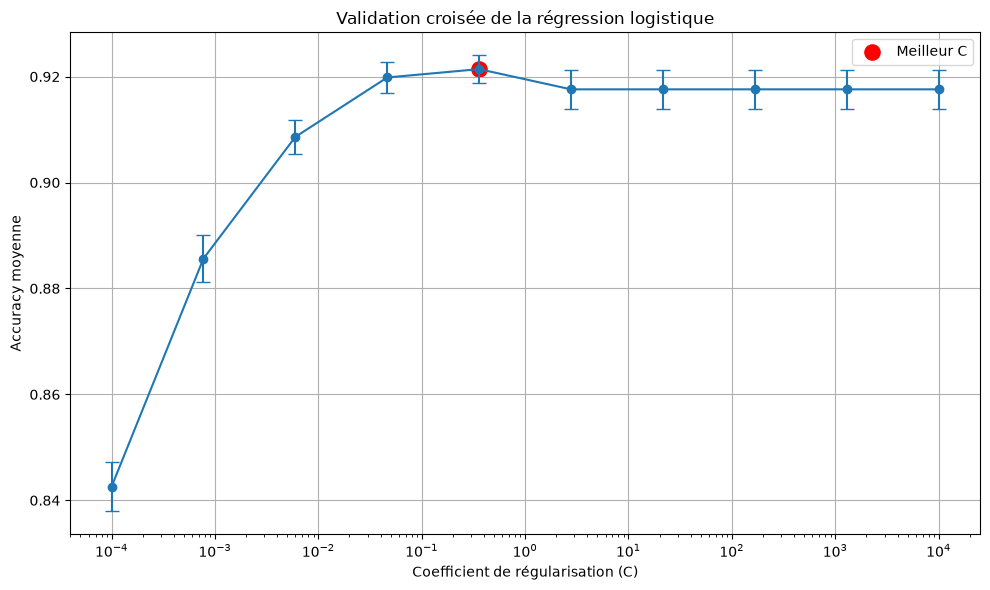

In [44]:
best_idx = np.argmax(mean_scores)

plt.figure(figsize=(10, 6))

plt.errorbar(
    baseline_model.Cs_,
    mean_scores,
    yerr=std_scores,
    fmt="o-",
    capsize=5,
)

plt.scatter(
    baseline_model.Cs_[best_idx],
    mean_scores[best_idx],
    color="red",
    s=120,
    label="Meilleur C",
)

plt.xscale("log")

plt.title("Validation croisée de la régression logistique")

plt.xlabel("Coefficient de régularisation (C)")

plt.ylabel("Accuracy moyenne")

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.savefig(
    "../reports/figures/baseline_cross_validation.png",
    bbox_inches="tight",
)

plt.show()

# Analyse statistique de la validation croisée

La validation croisée à 10 folds a permis d'évaluer l'influence du coefficient de régularisation sur les performances du modèle.

Les résultats montrent que :

- une régularisation trop forte (faibles valeurs de C) entraîne une baisse importante des performances ;
- les performances augmentent progressivement lorsque la régularisation diminue ;
- un optimum est atteint pour :

```text
C = 0.359381
```

avec :

```text
Accuracy moyenne = 92.14 %
Écart-type = 0.26 %
```

L'intervalle de confiance à 95 % associé est :

```text
[91.95 % ; 92.33 %]
```

La faible valeur de l'écart-type indique que les performances observées varient peu d'un fold à l'autre.

Le modèle apparaît donc robuste vis-à-vis du découpage des données utilisé pour la validation croisée.

Au-delà de la valeur optimale de C, les performances diminuent légèrement puis se stabilisent, ce qui suggère qu'une diminution supplémentaire de la régularisation n'apporte aucun bénéfice significatif.

Ces résultats justifient le choix automatique du coefficient de régularisation réalisé par LogisticRegressionCV.

# Modèle final retenu

À l'issue de la validation croisée, le coefficient de régularisation optimal est sélectionné automatiquement.

Le modèle correspondant sera utilisé pour l'évaluation finale sur l'ensemble de validation indépendant.

Conformément au protocole expérimental, cet ensemble de validation n'a jamais été utilisé au cours de la validation croisée.

In [45]:
best_idx = np.argmax(mean_scores)

best_c = baseline_model.Cs_[best_idx]

print(f"C optimal : {best_c:.6f}")

mean_accuracy = mean_scores[best_idx]
std_accuracy = std_scores[best_idx]

print(f"Accuracy CV : {mean_accuracy:.4%}")

print(f"Écart-type CV : {std_accuracy:.4%}")

C optimal : 0.359381
Accuracy CV : 92.1407%
Écart-type CV : 0.2642%


In [46]:
cv_summary = pd.DataFrame(
    {
        "C optimal": [best_c],
        "Accuracy CV": [mean_accuracy],
        "Écart-type CV": [std_accuracy],
    }
)

cv_summary

,C optimal,Accuracy CV,Écart-type CV
0,0.359381,0.921407,0.002642


In [47]:
cv_summary.to_csv(
    "../reports/experiments/baseline_cv_summary.csv",
    index=False,
)

---

# Évaluation sur l'ensemble de validation

La validation croisée a permis de sélectionner automatiquement le coefficient de régularisation optimal.

Nous évaluons maintenant le modèle final sur l'ensemble de validation indépendant.

Cet ensemble n'a jamais été utilisé pour :

- l'entraînement ;
- la sélection du coefficient de régularisation ;
- le choix du modèle.

Les performances observées constituent donc une estimation indépendante de la capacité de généralisation de la baseline.

# Prédictions

In [48]:
y_val_pred = baseline_model.predict(x_val_flat)

In [53]:
print(f"Nombre de prédictions : {len(y_val_pred)} / {len(y_val)}")

Nombre de prédictions : 6000 / 6000


# Métriques d'évaluation

Plusieurs métriques complémentaires sont utilisées.

## Accuracy

Proportion globale de prédictions correctes.

## Precision macro

Moyenne de la précision calculée indépendamment pour chacune des classes.

## Recall macro

Moyenne du rappel calculé indépendamment pour chacune des classes.

## F1-score macro

Moyenne harmonique entre précision et rappel.

Les versions macro sont retenues afin d'accorder le même poids à chacune des dix classes du problème.

In [54]:
accuracy = accuracy_score(
    y_val,
    y_val_pred,
)

precision = precision_score(
    y_val,
    y_val_pred,
    average="macro",
)

recall = recall_score(
    y_val,
    y_val_pred,
    average="macro",
)

f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro",
)

In [56]:
results_df = pd.DataFrame(
    {
        "Métrique": [
            "Accuracy",
            "Precision macro",
            "Recall macro",
            "F1-score macro",
        ],
        "Valeur": [
            accuracy,
            precision,
            recall,
            f1,
        ],
    }
)

results_df
results_df.to_csv(
    "../reports/experiments/baseline_metrics.csv",
    index=False,
)

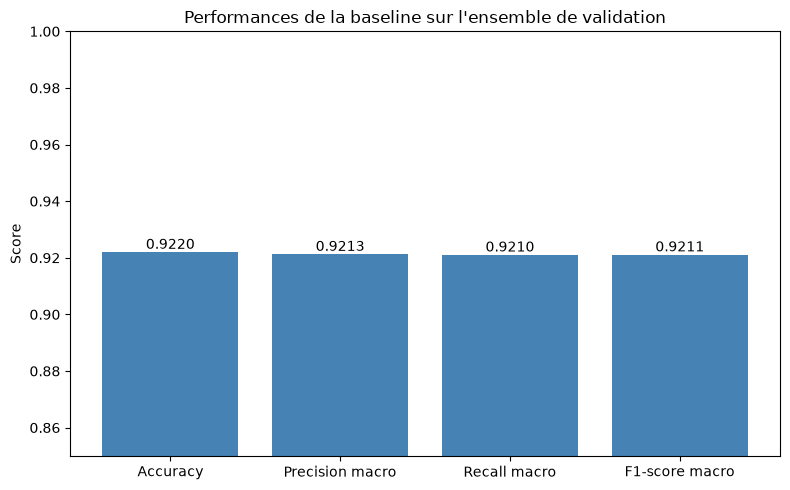

In [57]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    results_df["Métrique"],
    results_df["Valeur"],
    color="steelblue",
)

for bar in bars:
    value = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.4f}",
        ha="center",
        va="bottom",
    )

plt.ylim(0.85, 1.0)

plt.title("Performances de la baseline sur l'ensemble de validation")

plt.ylabel("Score")

plt.tight_layout()

plt.savefig(
    "../reports/figures/baseline_metrics.png",
    bbox_inches="tight",
)

plt.show()

# Estimation de l'incertitude sur l'ensemble de validation

L'ensemble de validation ne fournit qu'une mesure ponctuelle des performances.

Afin d'estimer l'incertitude associée à cette mesure, un bootstrap est réalisé.

Le bootstrap consiste à rééchantillonner plusieurs fois l'ensemble de validation avec remise afin d'obtenir une distribution empirique de l'accuracy.

In [58]:
n_bootstrap = 1000

bootstrap_scores = []

for _ in range(n_bootstrap):
    indices = np.random.choice(
        len(y_val),
        size=len(y_val),
        replace=True,
    )

    score = accuracy_score(
        y_val[indices],
        y_val_pred[indices],
    )

    bootstrap_scores.append(score)

bootstrap_scores = np.array(bootstrap_scores)

In [59]:
bootstrap_mean = bootstrap_scores.mean()

bootstrap_std = bootstrap_scores.std(ddof=1)

ci_low = np.percentile(
    bootstrap_scores,
    2.5,
)

ci_high = np.percentile(
    bootstrap_scores,
    97.5,
)

print(f"Accuracy bootstrap : {bootstrap_mean:.4%}")

print(f"Écart-type bootstrap : {bootstrap_std:.4%}")

print(f"IC95 % : [{ci_low:.4%} ; {ci_high:.4%}]")

Accuracy bootstrap : 92.1793%
Écart-type bootstrap : 0.3412%
IC95 % : [91.5000% ; 92.8342%]


In [61]:
bootstrap_summary = pd.DataFrame(
    {
        "Metric": ["Accuracy"],
        "Mean": [bootstrap_mean],
        "Std": [bootstrap_std],
        "CI95_low": [ci_low],
        "CI95_high": [ci_high],
    }
)

bootstrap_summary
bootstrap_summary.to_csv(
    "../reports/experiments/baseline_bootstrap_results.csv",
    index=False,
)

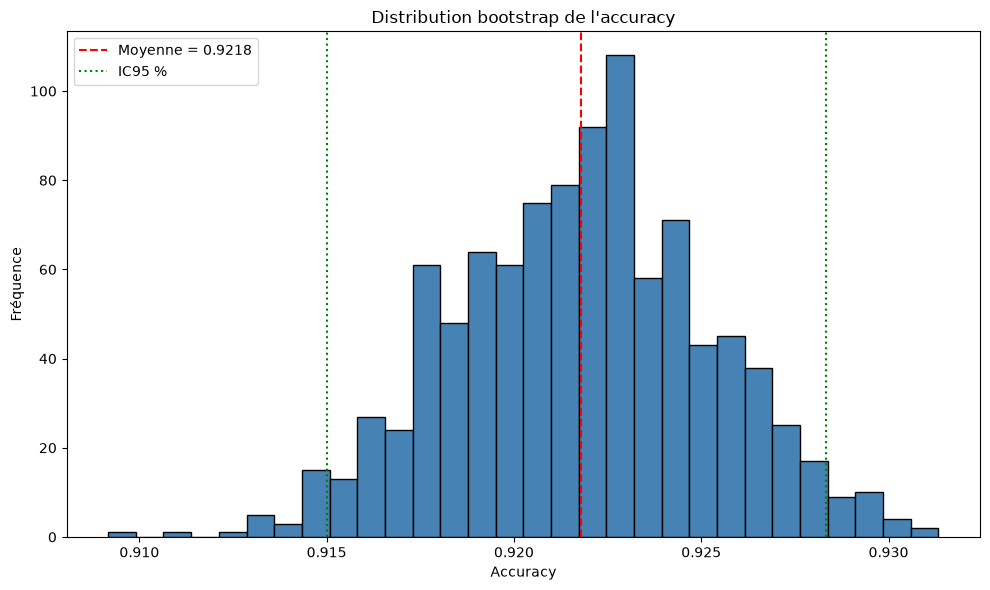

In [62]:
plt.figure(figsize=(10, 6))

plt.hist(
    bootstrap_scores,
    bins=30,
    color="steelblue",
    edgecolor="black",
)

plt.axvline(
    bootstrap_mean,
    color="red",
    linestyle="--",
    label=f"Moyenne = {bootstrap_mean:.4f}",
)

plt.axvline(ci_low, color="green", linestyle=":", label="IC95 %")

plt.axvline(ci_high, color="green", linestyle=":")

plt.title("Distribution bootstrap de l'accuracy")

plt.xlabel("Accuracy")
plt.ylabel("Fréquence")

plt.legend()

plt.tight_layout()

plt.savefig("../reports/figures/baseline_bootstrap_accuracy.png", bbox_inches="tight")

plt.show()

# Analyse de l'incertitude sur l'ensemble de validation

Un bootstrap à 1000 rééchantillonnages a été réalisé afin d'estimer l'incertitude associée aux performances observées sur l'ensemble de validation.

Les résultats obtenus sont :

- Accuracy moyenne : 92,18 % ;
- Écart-type : 0,34 % ;
- IC95 % : [91,50 % ; 92,83 %].

L'accuracy observée sur l'ensemble de validation (92,20 %) se situe au centre de cet intervalle.

Ces résultats renforcent la confiance dans la stabilité des performances du modèle et suggèrent que les résultats obtenus ne dépendent pas fortement d'un sous-échantillonnage particulier des données.

# Analyse globale des résultats

L'expérimentation réalisée permet d'évaluer la capacité d'une régression logistique à résoudre le problème de classification des chiffres manuscrits MNIST.

La validation croisée à 10 folds a mis en évidence un coefficient de régularisation optimal :

C = 0.359381

Pour cette valeur, les performances moyennes observées sont :

- Accuracy moyenne : 92,14 %
- Écart-type : 0,26 %
- IC95 % : [91,95 % ; 92,33 %]

La faible dispersion observée entre les folds indique une bonne stabilité du modèle vis-à-vis du découpage des données d'entraînement.

L'évaluation réalisée sur l'ensemble de validation indépendant confirme ces observations :

- Accuracy : 92,20 %
- Precision macro : 92,13 %
- Recall macro : 92,10 %
- F1-score macro : 92,11 %

Les différentes métriques présentent des valeurs très proches, ce qui est cohérent avec l'équilibre des classes observé lors de l'analyse exploratoire.

L'écart extrêmement faible entre l'accuracy moyenne obtenue durant la validation croisée et l'accuracy mesurée sur l'ensemble de validation suggère une bonne capacité de généralisation du modèle et l'absence de surapprentissage significatif.

# Analyse de l'incertitude et de la robustesse

Afin d'estimer l'incertitude associée aux performances observées sur l'ensemble de validation, un bootstrap à 1 000 rééchantillonnages a été réalisé.

Les résultats obtenus sont :

- Accuracy moyenne bootstrap : 92,18 %
- Écart-type bootstrap : 0,34 %
- IC95 % : [91,50 % ; 92,83 %]

L'accuracy observée sur l'ensemble de validation (92,20 %) se situe au centre de cet intervalle de confiance.

Cette cohérence entre :

- validation croisée ;
- validation indépendante ;
- bootstrap ;

renforce la confiance dans les performances observées.

Les résultats obtenus apparaissent donc robustes et peu sensibles aux fluctuations dues au découpage des données.


# Limites de la baseline

Malgré des performances satisfaisantes, la régression logistique présente plusieurs limitations.

Chaque pixel est traité comme une caractéristique indépendante, sans prise en compte explicite de la structure spatiale des images.

Le modèle ne peut donc pas exploiter efficacement :

- les motifs locaux ;
- les formes géométriques ;
- les relations entre pixels voisins.

Cette limitation explique vraisemblablement pourquoi les performances plafonnent autour de 92 %.

Les futurs modèles de Deep Learning, notamment les réseaux de neurones convolutifs, devraient être capables de mieux exploiter la structure des images et d'améliorer significativement les performances obtenues.

# Conclusion BASELINE-01

Une baseline reproductible fondée sur une régression logistique avec validation croisée a été construite avec succès.

La validation croisée à 10 folds a permis de sélectionner automatiquement un coefficient de régularisation optimal :

C = 0.359381

Les performances observées sont :

- Accuracy moyenne CV : 92,14 % ± 0,26 %
- IC95 % CV : [91,95 % ; 92,33 %]

L'évaluation sur l'ensemble de validation indépendant donne :

- Accuracy : 92,20 %
- Precision macro : 92,13 %
- Recall macro : 92,10 %
- F1-score macro : 92,11 %

Le bootstrap confirme la stabilité de ces résultats avec un intervalle de confiance à 95 % de :

[91,50 % ; 92,83 %]

Cette baseline fournit désormais une référence solide pour l'ensemble du projet.

Les prochaines étapes consisteront à :

- analyser les erreurs du modèle ;
- étudier sa matrice de confusion ;
- identifier les chiffres les plus difficiles à reconnaître ;

avant de comparer ces résultats aux futurs modèles MLP puis CNN.